# Marketing Mix Modeling con Google Meridian — demo paso a paso

**Caso:** *Tiendas Pacífico* (retailer ficticio) vende en 10 regiones del Perú y pauta en
TV, YouTube, Meta, Google Search y TikTok. Tenemos 104 semanas de datos **sintéticos**.

**¿Por qué datos sintéticos?** Porque nosotros fijamos el ROI real de cada canal al fabricar
los datos. Así podemos hacer algo imposible con datos reales: **verificar si el modelo
descubre la verdad**.

**Ruta del notebook**
1. Generar y explorar los datos
2. Cargar los datos en Meridian (`InputData`)
3. Especificar el modelo y los *priors* (`ModelSpec`)
4. Ajustar con MCMC (NUTS)
5. Diagnosticar: convergencia y ajuste
6. Resultados: ROI vs. verdad, contribución, curvas de respuesta, adstock
7. Optimizar el presupuesto
8. Guardar el modelo y exportar el reporte

In [1]:
import os, sys, json, warnings
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

# Permite importar mmm_core desde la carpeta del proyecto
RAIZ = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, RAIZ)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import meridian
from meridian import constants
from meridian.data import data_frame_input_data_builder as dfb
from meridian.model import model, spec, prior_distribution
from meridian.analysis import analyzer, visualizer, optimizer, summarizer

from mmm_core.datos_sinteticos import generar_datos, CANALES, NOMBRES_CANALES
from mmm_core import modelo as utilidades  # funciones auxiliares (tablas, símbolo S/)

print("Meridian", meridian.__version__)
plt.rcParams.update({"figure.figsize": (12, 4), "axes.spines.top": False, "axes.spines.right": False})

Meridian 2.1.0


## 1. Datos sintéticos

El generador simula, para cada región *g* y semana *t*:

$$\text{ventas}_{g,t} = \text{base}_{g,t} \cdot \text{tendencia} \cdot \text{estacionalidad} \cdot \text{precio}^{-1.2} \cdot (1 + 0.35\,\text{evento}) + \sum_m \beta_m \cdot \text{pob}_g \cdot \text{Hill}\big(\text{Adstock}(x_{m,g,t})\big) + \varepsilon$$

donde $x$ son las impresiones per cápita. Cada $\beta_m$ se calibra para que el ROI real
sea exactamente el que fijamos.

In [2]:
df, verdad = generar_datos()          # semilla fija = resultados reproducibles
print(df.shape)
df.head()

(1040, 16)


,geo,time,population,ventas,indice_precio,evento_comercial,tv_impresiones,tv_inversion,youtube_impresiones,youtube_inversion,meta_impresiones,meta_inversion,google_search_impresiones,google_search_inversion,tiktok_impresiones,tiktok_inversion
0,Lima,2024-10-07,10900000.0,1.834533e+06,0.979128,0.5,6.475920e+06,81755.544687,4.635949e+06,36252.803936,4.306176e+06,27779.692528,864879.859285,23532.625678,0.0,0.0
1,Lima,2024-10-14,10900000.0,1.670949e+06,0.968586,0.0,3.377141e+06,42634.866214,3.953394e+06,30915.268749,4.689392e+06,30251.865701,620346.659196,16879.090853,0.0,0.0
2,Lima,2024-10-21,10900000.0,1.637474e+06,0.954865,0.0,5.220416e+06,65905.380207,3.377415e+06,26411.150556,3.804610e+06,24544.026203,747467.776044,20337.945428,0.0,0.0
3,Lima,2024-10-28,10900000.0,1.596304e+06,0.968776,0.0,4.503709e+06,56857.278567,2.789931e+06,21817.072453,3.796262e+06,24490.175125,766004.902275,20842.324445,0.0,0.0
4,Lima,2024-11-04,10900000.0,1.631490e+06,0.972307,0.0,0.000000e+00,0.000000,2.884468e+06,22556.341338,3.159975e+06,20385.400787,977189.606991,26588.475834,0.0,0.0


In [3]:
pd.DataFrame(verdad["canales"]).T[["roi_real", "alpha_adstock", "inversion_total", "contribucion_total", "share_ventas"]] \
    .rename(index=NOMBRES_CANALES).style.format({"roi_real": "{:.2f}", "alpha_adstock": "{:.2f}",
        "inversion_total": "S/ {:,.0f}", "contribucion_total": "S/ {:,.0f}", "share_ventas": "{:.1%}"})

,roi_real,alpha_adstock,inversion_total,contribucion_total,share_ventas
TV,1.60,0.70,"S/ 7,191,939","S/ 11,507,102",3.1%
YouTube,1.10,0.50,"S/ 4,173,770","S/ 4,591,146",1.2%
Meta,2.40,0.30,"S/ 6,286,949","S/ 15,088,678",4.1%
Google Search,3.20,0.10,"S/ 5,264,923","S/ 16,847,753",4.5%
TikTok,0.90,0.35,"S/ 1,567,423","S/ 1,410,681",0.4%


> **La verdad de terreno.** Search es el canal más rentable (ROI 3.2) y TikTok el único que
> pierde dinero (ROI 0.9). TV tiene el arrastre más largo (α = 0.7). En total, los medios
> explican ~13 % de las ventas: el resto es línea base. Es una proporción realista y hace
> que el problema **no** sea fácil.

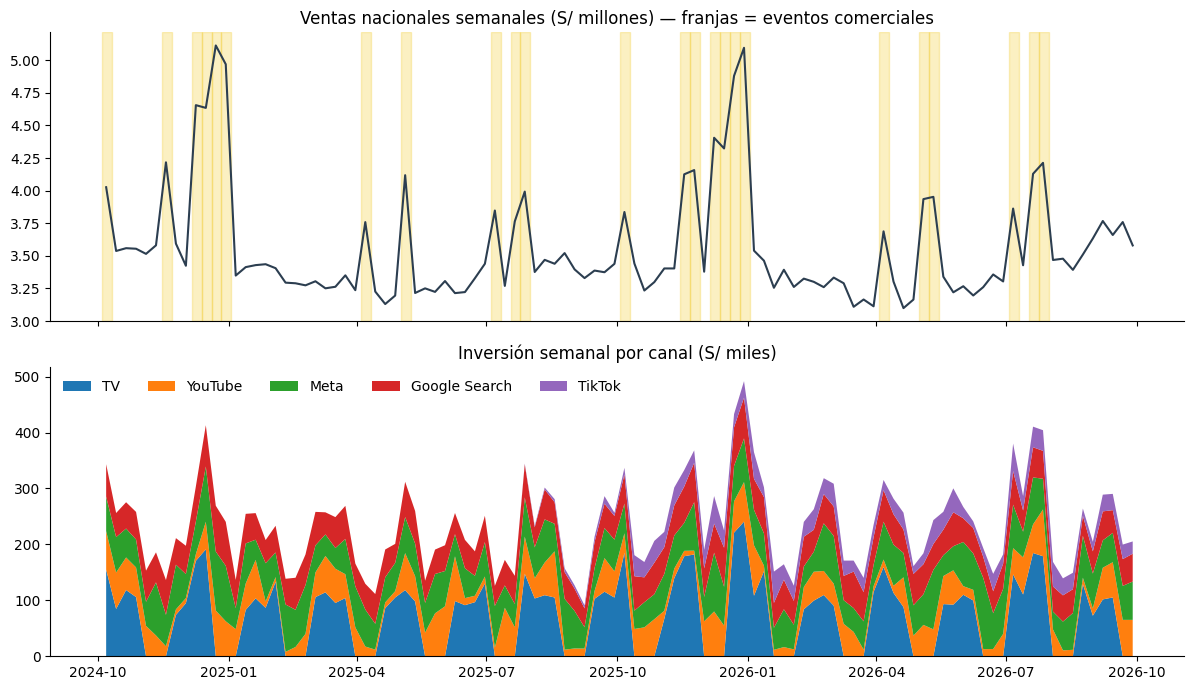

In [4]:
nacional = df.groupby("time").sum(numeric_only=True)
nacional.index = pd.to_datetime(nacional.index)

fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax[0].plot(nacional.index, nacional["ventas"] / 1e6, color="#2c3e50")
for f in nacional.index[nacional["evento_comercial"] > 0]:
    ax[0].axvspan(f - pd.Timedelta(days=3), f + pd.Timedelta(days=4), color="#f1c40f", alpha=0.25)
ax[0].set_title("Ventas nacionales semanales (S/ millones) — franjas = eventos comerciales")
ax[1].stackplot(nacional.index, *[nacional[f"{c}_inversion"] / 1e3 for c in CANALES],
                labels=[NOMBRES_CANALES[c] for c in CANALES])
ax[1].set_title("Inversión semanal por canal (S/ miles)")
ax[1].legend(loc="upper left", ncol=5, frameon=False)
plt.tight_layout()

Fíjate en los patrones de inversión: **TV va en *flights*** (4 semanas sí, 3 no), **TikTok
arranca a mitad del periodo** y **Search sigue a la demanda** (sube en eventos). Este último
detalle creará un problema de identificación que veremos en los resultados.

## 2. Cargar los datos en Meridian

Meridian recibe un objeto `InputData`. El `DataFrameInputDataBuilder` lo arma desde un
DataFrame largo (una fila por región-semana). Usamos `kpi_type="revenue"` porque el KPI ya
está en soles; si fueran conversiones, agregaríamos `revenue_per_kpi`.

In [5]:
builder = (
    dfb.DataFrameInputDataBuilder(kpi_type=constants.REVENUE)
    .with_kpi(df, kpi_col="ventas")
    .with_population(df, population_col="population")
    .with_controls(df, control_cols=["indice_precio", "evento_comercial"])
    .with_media(
        df,
        media_cols=[f"{c}_impresiones" for c in CANALES],      # exposición
        media_spend_cols=[f"{c}_inversion" for c in CANALES],  # costo
        media_channels=CANALES,
    )
)
builder.currency_code = "PEN"
input_data = builder.build()
input_data

InputData(kpi=<xarray.DataArray 'kpi' (geo: 10, time: 104)> Size: 8kB
array([[ 184204.92481892,  162354.47259651,  170163.73131735, ...,
         175515.51388456,  171803.52069925,  165417.52283729],
       [ 246065.8959542 ,  211127.08785683,  224054.49098772, ...,
         231168.30535566,  225778.14495613,  228152.31705776],
       [ 217373.80572399,  191462.66151366,  201580.8331715 , ...,
         205052.36688214,  194549.88664837,  211436.65004   ],
       ...,
       [1834533.15770493, 1670948.80814152, 1637473.50448097, ...,
        1648063.84290543, 1772607.6057129 , 1558246.36886673],
       [ 344214.15769015,  268033.82511061,  283767.22154252, ...,
         294931.66037259,  295782.25480322,  318892.60352693],
       [ 188404.50831443,  160264.59239269,  162806.66210492, ...,
         170793.42972868,  172517.70387557,  165253.88618016]],
      shape=(10, 104))
Coordinates:
  * geo      (geo) <U11 440B 'Ancash' 'Arequipa' 'Cajamarca' ... 'Piura' 'Puno'
  * time     (time) o

## 3. Especificación del modelo y *priors*

Decisiones clave del `ModelSpec`:

| Parámetro | Valor | Por qué |
|---|---|---|
| `media_prior_type="roi"` | prior sobre el **ROI** | Es la métrica que el negocio entiende; permite usar benchmarks o experimentos |
| `knots` | 13 (uno cada 8 semanas) | Línea base flexible pero sin absorber el efecto de los medios |
| `max_lag` | 8 semanas | Ventana máxima de adstock |

El prior por defecto del ROI es `LogNormal(0.2, 0.9)`: mediana ≈ 1.2, y 90 % de la masa
entre ~0.3 y ~5.4. Es deliberadamente vago.

**Ejercicio:** cambia `PRIORS_ROI` por un dict `{canal: (media, desviación)}` (por ejemplo,
resultados de un geo-lift para Search) y compara.

In [6]:
PRIORS_ROI = None   # ej.: {"tv": (1.5, 0.7), "youtube": (1.2, 0.6), "meta": (2, 1), "google_search": (3, 0.8), "tiktok": (1, 0.6)}

if PRIORS_ROI:
    from meridian import backend
    d = prior_distribution.lognormal_dist_from_mean_std([PRIORS_ROI[c][0] for c in CANALES],
                                                        [PRIORS_ROI[c][1] for c in CANALES])
    prior = prior_distribution.PriorDistribution(
        roi_m=backend.tfd.LogNormal(d.loc, d.scale, name=constants.ROI_M))
else:
    prior = prior_distribution.PriorDistribution()

model_spec = spec.ModelSpec(
    prior=prior,
    media_prior_type=constants.TREATMENT_PRIOR_TYPE_ROI,
    knots=13,
    max_lag=8,
)
mmm = model.Meridian(input_data=input_data, model_spec=model_spec)

## 4. Ajuste con MCMC

Meridian usa **NUTS** (No-U-Turn Sampler). Primero muestrea del prior (útil para comparar
prior vs posterior) y luego del posterior.

- `n_chains`: cadenas independientes (permiten medir convergencia).
- `n_adapt` + `n_burnin`: iteraciones de calentamiento que se descartan.
- `n_keep`: muestras que se conservan por cadena.

Para la clase usamos un preset rápido (~2–3 min en CPU). Para resultados finales Google
recomienda `n_chains=4, n_adapt=2000, n_burnin=500, n_keep=1000`.

In [7]:
%%time
PRESET = utilidades.PRESETS["Rápido (demo en vivo)"]   # o "Estándar" / "Producción"

mmm.sample_prior(300, seed=42)
mmm.sample_posterior(n_chains=PRESET.n_chains, n_adapt=PRESET.n_adapt,
                     n_burnin=PRESET.n_burnin, n_keep=PRESET.n_keep, seed=42)

CPU times: user 3min 26s, sys: 12.7 s, total: 3min 39s
Wall time: 2min 29s


## 5. Diagnóstico

### 5.1 Convergencia: R-hat
R-hat compara la varianza entre cadenas con la varianza dentro de cada cadena. **Si R-hat < 1.2**
(idealmente < 1.1) las cadenas coinciden y podemos confiar en el posterior.

In [8]:
an = analyzer.Analyzer(mmm)
an.rhat_summary()[["param", "n_params", "avg_r_hat", "max_r_hat", "percent_bad_r_hat"]].round(3)

,param,n_params,avg_r_hat,max_r_hat,percent_bad_r_hat
0,alpha_m,5.0,1.002,1.009,0.0
1,beta_gm,50.0,1.001,1.031,0.0
2,beta_m,5.0,1.000,1.005,0.0
3,ec_m,5.0,1.003,1.013,0.0
4,eta_m,5.0,1.009,1.034,0.0
5,gamma_c,2.0,0.997,0.997,0.0
6,gamma_gc,20.0,0.998,1.010,0.0
7,knot_values,13.0,1.014,1.019,0.0
8,mu_t,104.0,1.014,1.019,0.0
9,roi_m,5.0,1.002,1.015,0.0


In [9]:
visualizer.ModelDiagnostics(mmm).plot_rhat_boxplot()

alt.LayerChart(...)

### 5.2 Ajuste: ventas reales vs. esperadas
La **línea base** es lo que se habría vendido sin publicidad. La distancia entre lo esperado
y la línea base es el aporte de los medios.

In [10]:
visualizer.ModelFit(mmm).plot_model_fit()

alt.LayerChart(...)

In [11]:
an.predictive_accuracy().to_dataframe().reset_index() \
  .pivot_table(index="metric", columns="geo_granularity", values="value").round(3)

geo_granularity,geo,national
metric,,
MAPE,0.028,0.013
R_Squared,0.998,0.984
wMAPE,0.027,0.013


> Un R² alto **no** garantiza buenos ROI: un modelo puede predecir muy bien las ventas
> atribuyendo efectos al canal equivocado. Por eso la validación causal (experimentos)
> sigue siendo necesaria.

## 6. Resultados

### 6.1 ¿Recuperó el modelo el ROI real?

In [12]:
tabla = utilidades.tabla_roi(mmm, verdad)
tabla.drop(columns="canal").round(2)

,nombre,roi_estimado,ci_bajo,ci_alto,roi_real,error_%,real_dentro_ci
0,TV,1.56,0.92,2.37,1.6,-2.66,True
1,YouTube,1.00,0.33,2.12,1.1,-9.04,True
2,Meta,2.47,1.21,4.30,2.4,2.75,True
3,Google Search,1.99,0.59,3.78,3.2,-37.82,True
4,TikTok,1.21,0.25,3.01,0.9,34.65,True


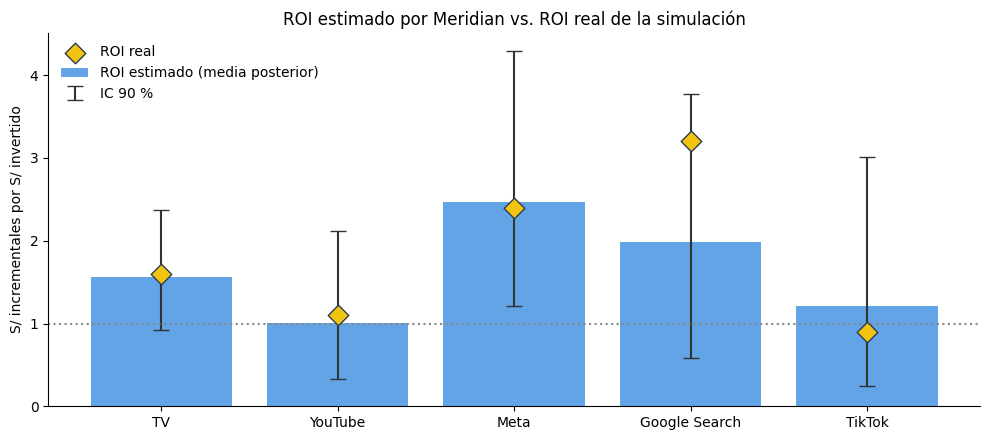

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(tabla))
ax.bar(x, tabla["roi_estimado"], color="#2e86de", alpha=0.75, label="ROI estimado (media posterior)")
ax.errorbar(x, tabla["roi_estimado"],
            yerr=[tabla["roi_estimado"] - tabla["ci_bajo"], tabla["ci_alto"] - tabla["roi_estimado"]],
            fmt="none", color="#333", capsize=6, label="IC 90 %")
ax.scatter(x, tabla["roi_real"], marker="D", s=110, color="#f1c40f", edgecolor="#2c3e50",
           zorder=3, label="ROI real")
ax.axhline(1, ls=":", color="#888")
ax.set_xticks(x, tabla["nombre"])
ax.set_ylabel("S/ incrementales por S/ invertido")
ax.set_title("ROI estimado por Meridian vs. ROI real de la simulación")
ax.legend(frameon=False)
plt.tight_layout()

**Qué observar**

- Si el ROI real (rombo) cae dentro del intervalo, el modelo es **consistente** con la verdad.
- **Google Search** tiende a quedar subestimado: su inversión sigue a la demanda y varía poco,
  así que el modelo atribuye parte de su efecto a la línea base. Es *endogeneidad*, el problema
  más común en MMM con canales de búsqueda.
- **TikTok** tiene el intervalo más ancho: empezó tarde y con poca inversión, hay poca señal.
- La incertidumbre es el mensaje: un canal con intervalo que cruza ROI = 1 pide un
  **experimento** antes de mover presupuesto.

### 6.2 Resumen por canal

In [14]:
media_summary = visualizer.MediaSummary(mmm)
media_summary.summary_table()

,channel,distribution,impressions,% impressions,spend,% spend,cpm,incremental outcome,% contribution,roi,effectiveness,mroi,cpik
0,tv,prior,"587,128,118",22%,"S/7,191,939",29%,S/12,"S/13,669,904 (S/1,779,688, S/38,542,472)","3.4% (0.4%, 9.6%)","1.9 (0.2, 5.4)","0.02 (0.00, 0.07)","1.0 (0.1, 2.9)","S/0.8 (S/0.2, S/4.0)"
1,tv,posterior,"587,128,118",22%,"S/7,191,939",29%,S/12,"S/11,201,235 (S/6,596,019, S/17,035,883)","3.0% (1.8%, 4.6%)","1.6 (0.9, 2.4)","0.02 (0.01, 0.03)","1.0 (0.6, 1.5)","S/0.7 (S/0.4, S/1.1)"
2,youtube,prior,"527,832,364",20%,"S/4,173,770",17%,S/8,"S/7,630,645 (S/1,140,856, S/23,179,934)","1.9% (0.3%, 5.7%)","1.8 (0.3, 5.6)","0.01 (0.00, 0.04)","0.8 (0.1, 3.0)","S/0.8 (S/0.2, S/3.7)"
3,youtube,posterior,"527,832,364",20%,"S/4,173,770",17%,S/8,"S/4,176,107 (S/1,361,384, S/8,853,319)","1.1% (0.4%, 2.4%)","1.0 (0.3, 2.1)","0.01 (0.00, 0.02)","0.5 (0.1, 1.1)","S/1.2 (S/0.5, S/3.1)"
4,meta,prior,"1,022,427,625",38%,"S/6,286,949",26%,S/6,"S/10,935,997 (S/1,864,407, S/30,031,741)","2.7% (0.5%, 7.4%)","1.7 (0.3, 4.8)","0.01 (0.00, 0.03)","0.8 (0.1, 2.6)","S/0.8 (S/0.2, S/3.4)"
5,meta,posterior,"1,022,427,625",38%,"S/6,286,949",26%,S/6,"S/15,503,971 (S/7,606,131, S/27,014,108)","4.2% (2.1%, 7.3%)","2.5 (1.2, 4.3)","0.02 (0.01, 0.03)","1.2 (0.6, 1.9)","S/0.4 (S/0.2, S/0.8)"
6,google_search,prior,"203,954,803",8%,"S/5,264,923",22%,S/26,"S/9,369,900 (S/1,390,672, S/26,044,845)","2.3% (0.3%, 6.5%)","1.8 (0.3, 4.9)","0.05 (0.01, 0.13)","0.8 (0.1, 2.3)","S/0.9 (S/0.2, S/3.8)"
7,google_search,posterior,"203,954,803",8%,"S/5,264,923",22%,S/26,"S/10,475,441 (S/3,093,739, S/19,877,137)","2.8% (0.8%, 5.4%)","2.0 (0.6, 3.8)","0.05 (0.02, 0.10)","1.1 (0.3, 1.9)","S/0.5 (S/0.3, S/1.7)"
8,tiktok,prior,"321,522,734",12%,"S/1,567,423",6%,S/5,"S/2,901,439 (S/404,171, S/8,987,164)","0.7% (0.1%, 2.2%)","1.9 (0.3, 5.7)","0.01 (0.00, 0.03)","0.8 (0.1, 2.3)","S/0.8 (S/0.2, S/3.9)"
9,tiktok,posterior,"321,522,734",12%,"S/1,567,423",6%,S/5,"S/1,899,552 (S/387,849, S/4,711,582)","0.5% (0.1%, 1.3%)","1.2 (0.2, 3.0)","0.01 (0.00, 0.01)","0.5 (0.1, 1.3)","S/1.1 (S/0.3, S/4.0)"


In [15]:
media_summary.plot_contribution_waterfall_chart()

alt.LayerChart(...)

In [16]:
media_summary.plot_roi_vs_mroi()

alt.Chart(...)

**ROI marginal (mROI)**: lo que rinde el *siguiente* sol. Un canal con ROI alto pero mROI < 1
ya está saturado: conviene mover presupuesto hacia canales con mROI alto.

### 6.3 Curvas de respuesta, adstock y saturación

In [17]:
media_effects = visualizer.MediaEffects(mmm)
media_effects.plot_response_curves(plot_separately=False)

alt.LayerChart(...)

In [18]:
media_effects.plot_adstock_decay()

alt.FacetChart(...)

In [19]:
hill = media_effects.plot_hill_curves()
list(hill.values())[0] if isinstance(hill, dict) else hill

alt.FacetChart(...)

## 7. Optimización del presupuesto

El `BudgetOptimizer` usa las curvas de respuesta para encontrar la mezcla que maximiza las
ventas incrementales, con restricciones de cuánto puede moverse cada canal.

### 7.1 Presupuesto fijo (mismo total, distinta mezcla, máximo ±30 % por canal)

In [20]:
%%time
opt = optimizer.BudgetOptimizer(mmm)
res_fijo = opt.optimize(fixed_budget=True, spend_constraint_lower=0.3, spend_constraint_upper=0.3)
utilidades.tabla_optimizacion(res_fijo).drop(columns="canal").round(0)

CPU times: user 46.2 s, sys: 469 ms, total: 46.7 s
Wall time: 30.4 s


,nombre,inversion_actual,inversion_optima,ventas_inc_actual,ventas_inc_optima,cambio_inversion_%
0,TV,7190000.0,7130000.0,11199291.0,11138951.0,-1.0
1,YouTube,4170000.0,2920000.0,4174302.0,3478448.0,-30.0
2,Meta,6290000.0,7680000.0,15507709.0,17052840.0,22.0
3,Google Search,5260000.0,5650000.0,10470151.0,10876323.0,7.0
4,TikTok,1570000.0,1100000.0,1900903.0,1610812.0,-30.0


In [21]:
res_fijo.plot_spend_delta()

alt.LayerChart(...)

In [22]:
res_fijo.plot_incremental_outcome_delta()

alt.LayerChart(...)

### 7.2 Presupuesto flexible: ¿cuánto invertir manteniendo un ROI mínimo de 1.5?

In [23]:
res_flex = opt.optimize(fixed_budget=False, target_roi=1.5,
                        spend_constraint_lower=0.5, spend_constraint_upper=0.5)
t = utilidades.tabla_optimizacion(res_flex)
print(f"Inversión total: S/ {t.inversion_actual.sum():,.0f} -> S/ {t.inversion_optima.sum():,.0f}")
t.drop(columns="canal").round(0)

Inversión total: S/ 24,480,000 -> S/ 34,840,000


,nombre,inversion_actual,inversion_optima,ventas_inc_actual,ventas_inc_optima,cambio_inversion_%
0,TV,7190000.0,10780000.0,11199291.0,14295713.0,50.0
1,YouTube,4170000.0,4790000.0,4174302.0,4452531.0,15.0
2,Meta,6290000.0,9440000.0,15507709.0,18645470.0,50.0
3,Google Search,5260000.0,7890000.0,10470151.0,12796937.0,50.0
4,TikTok,1570000.0,1940000.0,1900903.0,2074778.0,24.0


## 8. Guardar el modelo y exportar el reporte HTML de Meridian

In [24]:
os.makedirs(os.path.join(RAIZ, "modelos"), exist_ok=True)
model.save_mmm(mmm, os.path.join(RAIZ, "modelos", "modelo_notebook.pkl"))

summarizer.Summarizer(mmm).output_model_results_summary(
    "reporte_meridian.html", os.path.join(RAIZ, "modelos"))
res_fijo.output_optimization_summary("reporte_optimizacion.html", os.path.join(RAIZ, "modelos"))
print("Guardado en", os.path.join(RAIZ, "modelos"))

Guardado en modelos


## Para seguir explorando

1. **Priors calibrados:** define `PRIORS_ROI` con un prior informativo para Search
   (p. ej. `(3.0, 0.8)`, como si viniera de un geo-experimento) y observa cómo se corrige el sesgo.
2. **Más muestras:** usa el preset `"Estándar"` y compara R-hat e intervalos.
3. **Cambia la verdad:** `generar_datos(ConfigSimulacion(...))` con otros ROI o más ruido.
   ¿Con cuánto ruido el modelo deja de distinguir canales?
4. **Menos datos:** recorta a 52 semanas. ¿Qué pasa con la incertidumbre?
5. **Modelo nacional:** agrega todas las regiones en una sola y compara con el modelo geo.